# Benchmark - Performance, Scaling & Summary

- **Part A (Run Analysis):** Controlled subprocess timing and memory (`Max RSS` via `/usr/bin/time`) across read-count scaling (`1,000`–`50,000` ECDC ESIB EQA `EQA_2026_01` reads), read-length scaling (`200`–`4,000 nt` concatemers), primer-panel scaling (`2`–`214` primers), and `AmpliGone` thread scaling (`2`–`20` threads).
- **Part B (Results, Visualization & Conclusions):** Throughput and memory tables, scaling plots across all 4 axes, speed-vs-accuracy comparisons, and the summary and conclusions.

**Caching rule:** same as every other notebook

## Part A, Run Controlled Performance Benchmark

In [1]:
import hashlib
import itertools
import json
import os
from pathlib import Path
import subprocess
import sys
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import primer_matchers

MANUAL_DIR = ROOT / "manual_test"
DATASET_DIR = MANUAL_DIR / "datasets"
PROCESSED_DIR = MANUAL_DIR / "processed"
RESULTS_DIR = PROCESSED_DIR / "benchmark2"
PIPELINE_DIR = RESULTS_DIR / "pipeline"
PERFORMANCE_DIR = RESULTS_DIR / "performance"
PERFORMANCE_INPUT_DIR = PERFORMANCE_DIR / "inputs"
PERFORMANCE_SCRATCH_DIR = PERFORMANCE_DIR / "scratch"
PERFORMANCE_DIR.mkdir(parents=True, exist_ok=True)

REFERENCE_ID = "MN908947.3"
REFERENCE_FASTA = MANUAL_DIR / "MN908947.fasta"
SIM_YEAR = "2026"
PRIMER_FASTA = DATASET_DIR / f"ESIB_EQA_{SIM_YEAR}.SARS1.primers.fasta"
PRIMER_BED = DATASET_DIR / f"ESIB_EQA_{SIM_YEAR}.SARS1.primers.bed"

PERFORMANCE_SAMPLE = "EQA_2026_01"
PERFORMANCE_METHODS = ("bitvector_longest", "sassy", "semiglobal", "ampligone")
PERFORMANCE_BASELINE_READS = 10_000
PERFORMANCE_READ_COUNTS = (1_000, 5_000, 10_000, 50_000)
PERFORMANCE_READ_LENGTHS = (200, 500, 1_000, 2_000, 4_000)
PERFORMANCE_PRIMER_COUNTS = (2, 8, 32, 128, 214)
AMPLIGONE_THREAD_COUNTS = (2, 4, 8, 16, 20)
PERFORMANCE_AMPLIGONE_MIN_THREADS = 2
PERFORMANCE_REPLICATES = 5
PERFORMANCE_TIME_BINARY = Path("/usr/bin/time")
PERFORMANCE_TIME_FORMAT = "PERF|%e|%U|%S|%M"

PERFORMANCE_TRIALS_PATH = PERFORMANCE_DIR / "performance_trials.csv"
PERFORMANCE_SUMMARY_PATH = PERFORMANCE_DIR / "performance_summary.csv"
PERFORMANCE_PIPELINE_PATH = PERFORMANCE_DIR / "pipeline_stage_times.csv"

ENVS = {"main": "ampligone_thesis", "vc": "ampligone_thesis_vc"}
ENV_ROOT = Path(sys.prefix).parent

print(f"Performance directory: {PERFORMANCE_DIR}")
print(f"Reference FASTA:       {REFERENCE_FASTA}")

Performance directory: /home/zwagemaf/projects/AmpliGone_thesis/manual_test/processed/benchmark2/performance
Reference FASTA:       /home/zwagemaf/projects/AmpliGone_thesis/manual_test/MN908947.fasta


In [2]:
# 1. Run or Reuse Performance Benchmark Trials & Summarize

def summarize_performance(trials: pd.DataFrame) -> pd.DataFrame:
    successful = trials[trials["status"] == "ok"].copy()
    summary_rows = []
    group_columns = ["axis", "setting", "method", "threads"]
    for keys, group in successful.groupby(group_columns, sort=False):
        row = dict(zip(group_columns, keys))
        row["replicates"] = len(group)
        for metric in ("runtime_s", "reads_per_s", "kbp_per_s", "cpu_s", "max_rss_kb"):
            row[f"{metric}_median"] = group[metric].median()
            row[f"{metric}_q25"] = group[metric].quantile(0.25)
            row[f"{metric}_q75"] = group[metric].quantile(0.75)
        summary_rows.append(row)
    summary = pd.DataFrame(summary_rows)
    summary.to_csv(PERFORMANCE_SUMMARY_PATH, index=False)
    return summary


if PERFORMANCE_SUMMARY_PATH.is_file() and PERFORMANCE_TRIALS_PATH.is_file():
    print(f"Skipping performance benchmark execution (already exists: {PERFORMANCE_SUMMARY_PATH})")
elif PERFORMANCE_TRIALS_PATH.is_file():
    trials = pd.read_csv(PERFORMANCE_TRIALS_PATH)
    summarize_performance(trials)
    print(f"Summarized {len(trials)} trials into {PERFORMANCE_SUMMARY_PATH}")

Skipping performance benchmark execution (already exists: /home/zwagemaf/projects/AmpliGone_thesis/manual_test/processed/benchmark2/performance/performance_summary.csv)


---
## Part B — Results, Scaling Visualizations & Final Conclusions

In [3]:
# 1. Baseline Throughput & Peak Memory (10,000 EQA_2026_01 Reads, 214 Primers)
summary = pd.read_csv(PERFORMANCE_SUMMARY_PATH)
baseline = summary[summary["axis"] == "baseline"].copy()
baseline["max_rss_mb"] = baseline["max_rss_kb_median"] / 1024.0

cols = [
    "method", "threads", "replicates", "runtime_s_median", "reads_per_s_median",
    "kbp_per_s_median", "cpu_s_median", "max_rss_mb",
]
print("Controlled Baseline Performance (10,000 adapter-cleaned EQA_2026_01 reads, 214 primers):")
display(baseline[cols].set_index("method").round(2))

if PERFORMANCE_PIPELINE_PATH.is_file():
    stage_times = pd.read_csv(PERFORMANCE_PIPELINE_PATH)
    print("\nIndicative Full-Pipeline Stage Timings Across 70 ECDC ESIB EQA Samples (concurrent workload):")
    display(stage_times.groupby("method").agg(
        samples=("sample", "count"),
        end_to_end_s_median=("end_to_end_s", "median"),
        primer_removal_s_median=("primer_removal_s", "median"),
        align_s_median=("align_s", "median"),
        consensus_s_median=("consensus_s", "median"),
    ).round(2))

Controlled Baseline Performance (10,000 adapter-cleaned EQA_2026_01 reads, 214 primers):


,threads,replicates,runtime_s_median,reads_per_s_median,kbp_per_s_median,cpu_s_median,max_rss_mb
method,,,,,,,
bitvector_longest,1,10,55.38,180.55,69.63,57.10,58.43
sassy,1,10,42.76,234.03,90.26,44.50,331.42
semiglobal,1,10,106.36,94.04,36.27,108.08,67.40
ampligone,2,10,8.72,1146.80,442.27,18.22,163.10



Indicative Full-Pipeline Stage Timings Across 70 ECDC ESIB EQA Samples (concurrent workload):


,samples,end_to_end_s_median,primer_removal_s_median,align_s_median,consensus_s_median
method,,,,,
ampligone,70,210.80,34.38,2.89,161.78
bitvector_longest,70,312.38,134.36,2.84,165.16
no_trim,70,182.22,0.04,3.66,164.38
sassy,70,270.60,90.03,2.68,164.20
semiglobal,70,403.94,237.11,2.96,165.13


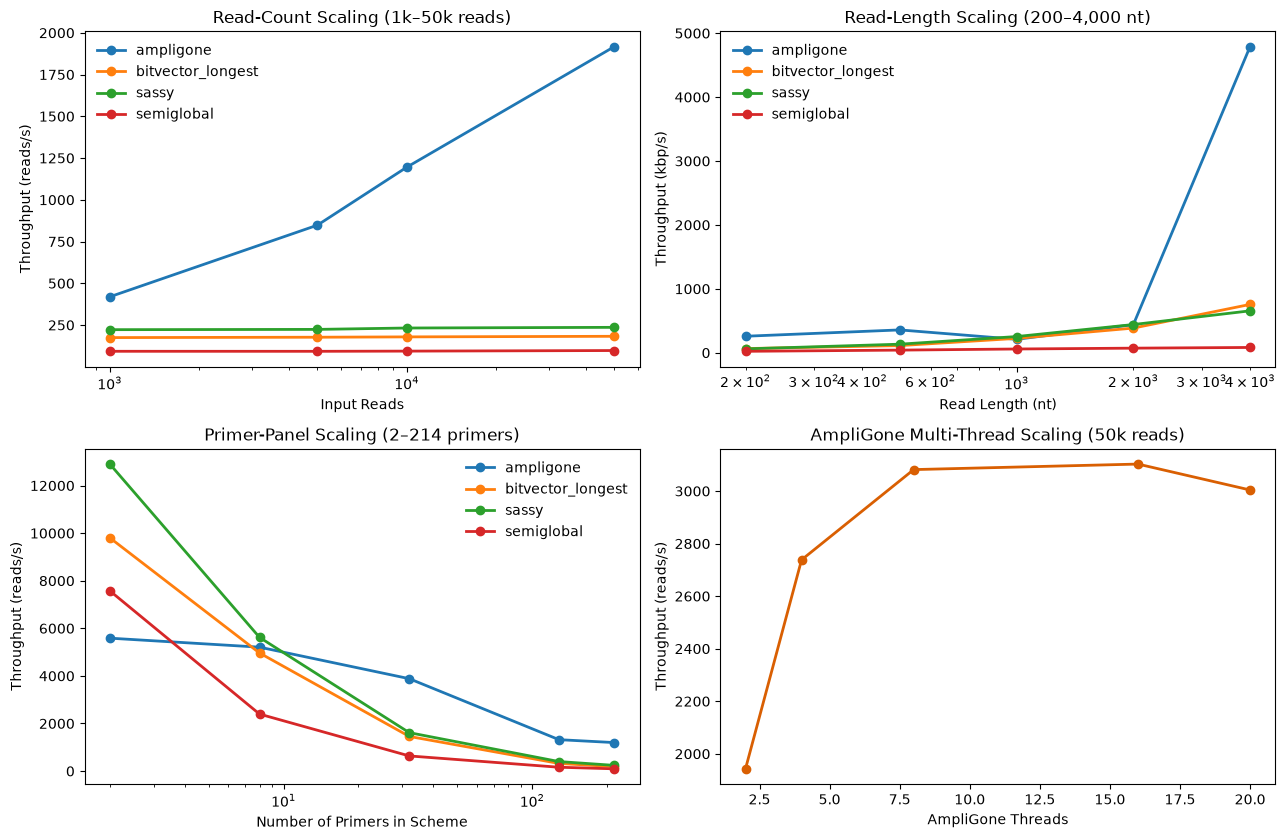

In [4]:
# 2. Scaling Across Read Count, Read Length, Primer Panel Size & AmpliGone Threads
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

for method, rows in summary[summary["axis"] == "read_count"].groupby("method"):
    rows = rows.sort_values("setting")
    axes[0, 0].plot(rows["setting"], rows["reads_per_s_median"], marker="o", linewidth=2, label=method)
axes[0, 0].set(xscale="log", xlabel="Input Reads", ylabel="Throughput (reads/s)", title="Read-Count Scaling (1k–50k reads)")
axes[0, 0].legend(frameon=False)

for method, rows in summary[summary["axis"] == "read_length"].groupby("method"):
    rows = rows.sort_values("setting")
    axes[0, 1].plot(rows["setting"], rows["kbp_per_s_median"], marker="o", linewidth=2, label=method)
axes[0, 1].set(xscale="log", xlabel="Read Length (nt)", ylabel="Throughput (kbp/s)", title="Read-Length Scaling (200–4,000 nt)")
axes[0, 1].legend(frameon=False)

for method, rows in summary[summary["axis"] == "primer_count"].groupby("method"):
    rows = rows.sort_values("setting")
    axes[1, 0].plot(rows["setting"], rows["reads_per_s_median"], marker="o", linewidth=2, label=method)
axes[1, 0].set(xscale="log", xlabel="Number of Primers in Scheme", ylabel="Throughput (reads/s)", title="Primer-Panel Scaling (2–214 primers)")
axes[1, 0].legend(frameon=False)

amp_threads = summary[(summary["axis"] == "ampligone_threads") & (summary["method"] == "ampligone")].sort_values("threads")
axes[1, 1].plot(amp_threads["threads"], amp_threads["reads_per_s_median"], marker="o", linewidth=2, color="#d95f02")
axes[1, 1].set(xlabel="AmpliGone Threads", ylabel="Throughput (reads/s)", title="AmpliGone Multi-Thread Scaling (50k reads)")

plt.tight_layout()
plt.show()

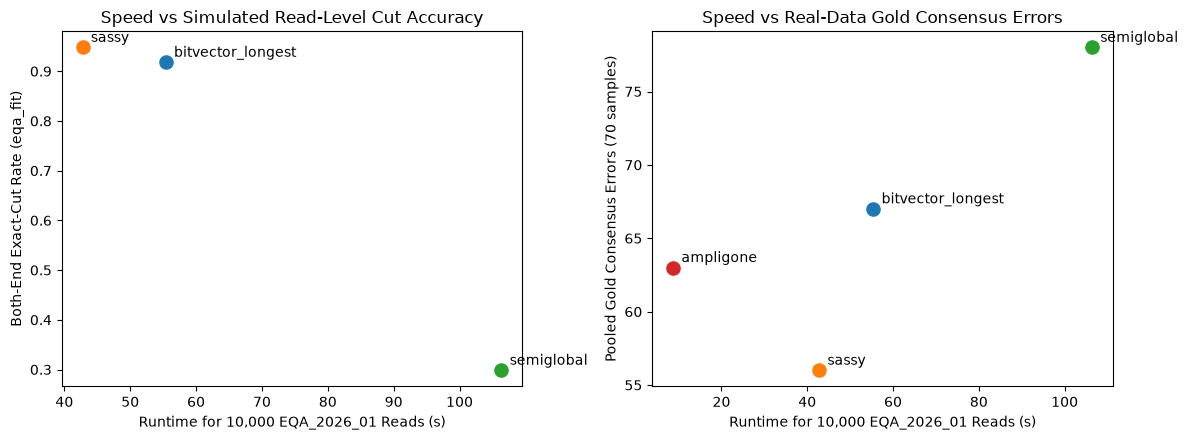

In [5]:
# 3. Speed vs Consensus Accuracy & Simulated Cut Accuracy Pareto Plots
base_idx = baseline.set_index("method")
cons_pooled = pd.read_csv(RESULTS_DIR / "consensus_evaluation.summary_pooled.csv")
cons_gold = cons_pooled[cons_pooled["standard"] == "gold"].set_index("method")
bound_prof = pd.read_csv(RESULTS_DIR / "scoring_boundary_by_profile.csv", index_col=[0, 1])
eqa_fit_exact = bound_prof.loc["eqa_fit", "both_exact"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for method in ("bitvector_longest", "sassy", "semiglobal"):
    rt = base_idx.loc[method, "runtime_s_median"]
    ex = eqa_fit_exact.loc[method]
    axes[0].scatter(rt, ex, s=90, label=method)
    axes[0].annotate(method, (rt, ex), xytext=(6, 4), textcoords="offset points")
axes[0].set(xlabel="Runtime for 10,000 EQA_2026_01 Reads (s)", ylabel="Both-End Exact-Cut Rate (eqa_fit)",
            title="Speed vs Simulated Read-Level Cut Accuracy")

for method in PERFORMANCE_METHODS:
    rt = base_idx.loc[method, "runtime_s_median"]
    err = cons_gold.loc[method, "total_errors"]
    axes[1].scatter(rt, err, s=90, label=method)
    axes[1].annotate(method, (rt, err), xytext=(6, 4), textcoords="offset points")
axes[1].set(xlabel="Runtime for 10,000 EQA_2026_01 Reads (s)", ylabel="Pooled Gold Consensus Errors (70 samples)",
            title="Speed vs Real-Data Gold Consensus Errors")

plt.tight_layout()
plt.show()